# 08 — Straddle acquisition and the stopping rule

2-D continuous Branin with a known boundary. Checks: straddle > 0 exactly where the 95%
interval contains tau; the picked point sits near the predicted boundary with high
uncertainty; and the "max straddle < 0" stop — when it fires and whether confident means correct.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mvlse import Continuous, DesignSpace, fit_surrogate, run_lse, score_level_set, straddle, stratified_doe
from mvlse.problems.functions import branin_h

space = DesignSpace({"x1": Continuous(0.0, 1.0), "x2": Continuous(0.0, 1.0)})   # branin_h is defined on [0, 1]^2
blackbox = lambda pts: branin_h(np.array([p["x1"] for p in pts]), np.array([p["x2"] for p in pts]))
n = 60
g1, g2 = np.meshgrid(np.linspace(0, 1, n), np.linspace(0, 1, n))
w_grid = np.column_stack([g1.ravel(), g2.ravel()])            # encoded (unit) coordinates
truth = blackbox(space.decode(w_grid))
TAU = float(np.quantile(truth, 0.3))                           # 30% of the domain inside
print(f"tau = {TAU:.2f}, true inside fraction = {np.mean(truth <= TAU):.2f}")

tau = -0.69, true inside fraction = 0.30


straddle > 0  <=>  95% interval contains tau: True
picked point: |mu - tau| = 0.00 (grid median 0.35), sd = 0.07 (grid median 0.00, percentile 99%)


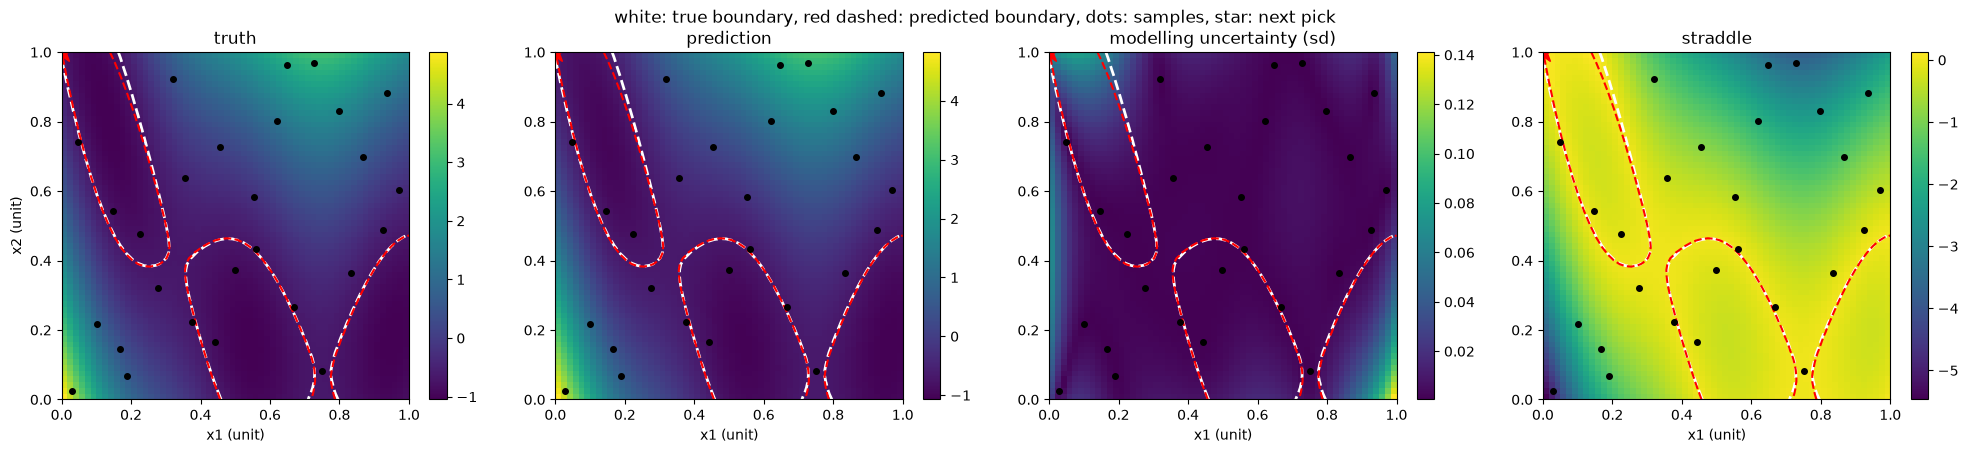

In [10]:
w0 = stratified_doe(space, 27, seed=1)
model = fit_surrogate("hs_dim", space, w0, blackbox(space.decode(w0)), rng=np.random.default_rng(0))
mu, sd = model.predict(w_grid)
a = straddle(mu, sd, TAU)
pick = int(np.argmax(a))

interval_contains_tau = (mu - 1.96 * sd < TAU) & (TAU < mu + 1.96 * sd)
print("straddle > 0  <=>  95% interval contains tau:", np.array_equal(a > 0, interval_contains_tau))
print(f"picked point: |mu - tau| = {abs(mu[pick] - TAU):.2f} (grid median {np.median(np.abs(mu - TAU)):.2f}), "
      f"sd = {sd[pick]:.2f} (grid median {np.median(sd):.2f}, percentile {np.mean(sd < sd[pick]):.0%})")

fig, axes = plt.subplots(1, 4, figsize=(20, 4.4))
for ax, (field, title) in zip(axes, ((truth, "truth"), (mu, "prediction"), (sd, "modelling uncertainty (sd)"), (a, "straddle"))):
    im = ax.imshow(field.reshape(n, n), origin="lower", extent=(0, 1, 0, 1), cmap="viridis")
    ax.contour(g1, g2, truth.reshape(n, n), levels=[TAU], colors="w", linewidths=2)
    ax.contour(g1, g2, mu.reshape(n, n), levels=[TAU], colors="r", linewidths=1.5, linestyles="--")
    ax.plot(w0[:, 0], w0[:, 1], "k.", ms=8)
    ax.plot(*w_grid[pick], "r*", ms=16)
    ax.set_title(title); ax.set_xlabel("x1 (unit)"); plt.colorbar(im, ax=ax, fraction=0.046)
axes[0].set_ylabel("x2 (unit)")
fig.suptitle("white: true boundary, red dashed: predicted boundary, dots: samples, star: next pick")
plt.tight_layout(); plt.show()

stop: confident (max straddle < 0) after 27 samples
at stop: F1 = 0.9921, ambiguous fraction = 0.89%, misclassified grid points = 17 of 3600


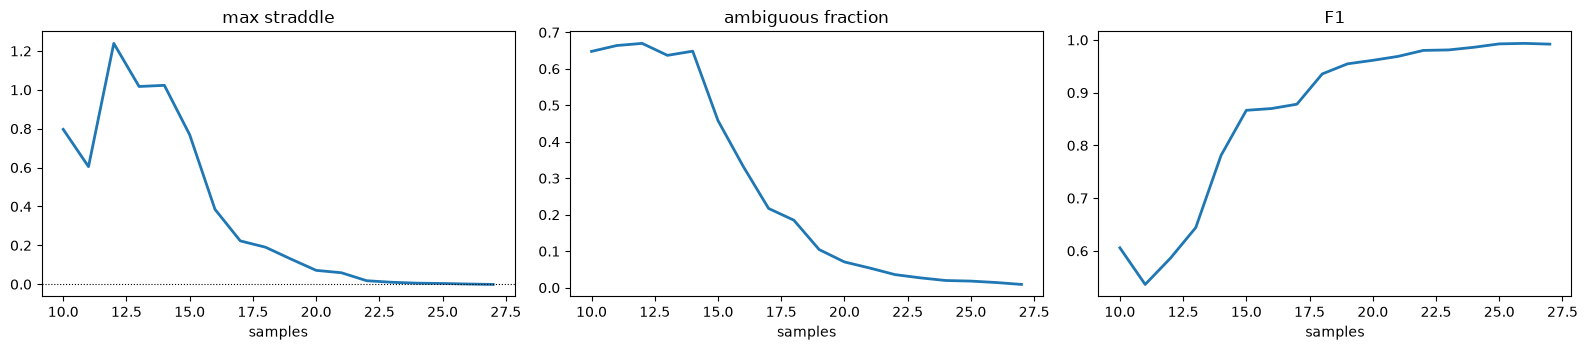

In [11]:
# Full loop with no plateau stop: only "confident" or the budget can end it.
res = run_lse(space, blackbox, threshold=TAU, max_evaluations=150, n_init_per_category=10,
              flip_tolerance=-1.0, monitor=w_grid, keep_snapshots=True, verbose=False, seed=1)
f1 = [score_level_set(m, truth, TAU).f1 for m, _ in res.snapshots]
hist = pd.DataFrame({"n": [r.n_evaluations for r in res.rounds], "max straddle": [r.max_straddle for r in res.rounds],
                     "ambiguous fraction": [r.ambiguous_fraction for r in res.rounds], "F1": f1})
print(f"stop: {res.stop_reason} after {res.n_evaluations} samples")
print(f"at stop: F1 = {f1[-1]:.4f}, ambiguous fraction = {hist['ambiguous fraction'].iloc[-1]:.2%}, "
      f"misclassified grid points = {np.sum((res.snapshots[-1][0] <= TAU) != (truth <= TAU))} of {len(truth)}")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
for ax, col in zip(axes, ("max straddle", "ambiguous fraction", "F1")):
    ax.plot(hist["n"], hist[col], lw=2); ax.set_xlabel("samples"); ax.set_title(col)
axes[0].axhline(0, color="k", lw=0.8, ls=":")
plt.tight_layout(); plt.show()